In [ ]:
!pip -q install librosa soundfile matplotlib numpy pandas jiwer transformers accelerate sentencepiece gTTS

In [ ]:
import os
import requests
from pathlib import Path

AUDIO_URL = "https://stutterrockstar.files.wordpress.com/2011/05/male-episode-1-with-alan1.mp3"
AUDIO_PATH = "/content/stutter_audio.mp3"

if not os.path.exists(AUDIO_PATH):
    response = requests.get(AUDIO_URL, timeout=120)
    response.raise_for_status()
    with open(AUDIO_PATH, "wb") as f:
        f.write(response.content)

print(f"Audio saved to: {AUDIO_PATH}")
print(f"File size: {os.path.getsize(AUDIO_PATH) / (1024*1024):.2f} MB")

Audio saved to: /content/stutter_audio.mp3
File size: 51.29 MB


## Feature extraction
Feature extraction converts the raw audio signal into meaningful numerical representations that capture important speech characteristics. In this activity, the audio is transformed into Log-Mel spectral features, which help represent frequency and energy variations over time for speech analysis and recognition.

In [ ]:
import numpy as np
import librosa
import soundfile as sf
from IPython.display import Audio, display

TARGET_SR = 16000
CLIP_SECONDS = 60
CLIP_START_SECONDS = 20

full_audio, full_sr = librosa.load(AUDIO_PATH, sr=TARGET_SR, mono=True)
full_duration = len(full_audio) / TARGET_SR

if full_duration < CLIP_SECONDS:
    raise ValueError(f"Source audio is only {full_duration:.1f} seconds; a full 60-second clip is not available.")

start_sample = int(CLIP_START_SECONDS * TARGET_SR)
end_sample = int((CLIP_START_SECONDS + CLIP_SECONDS) * TARGET_SR)
if end_sample > len(full_audio):
    raise ValueError("Chosen clip runs past the end of the audio. Reduce CLIP_START_SECONDS.")

clip = full_audio[start_sample:end_sample]
CLIP_PATH = "/content/stutter_clip_60s.wav"
sf.write(CLIP_PATH, clip, TARGET_SR)

print(f"Full audio duration: {full_duration/60:.2f} minutes")
print(f"Selected clip: {CLIP_START_SECONDS}–{CLIP_START_SECONDS + CLIP_SECONDS} seconds")
print(f"Clip duration: {len(clip)/TARGET_SR:.1f} seconds")
display(Audio(clip, rate=TARGET_SR))

Full audio duration: 56.02 minutes
Selected clip: 20–80 seconds
Clip duration: 60.0 seconds


## Waveform and its analysis
The waveform shows amplitude variations in the speech signal over 60 seconds, with peaks representing higher vocal energy and low-amplitude regions indicating pauses or reduced energy. These variations help visualize speech patterns and identify possible stutters.







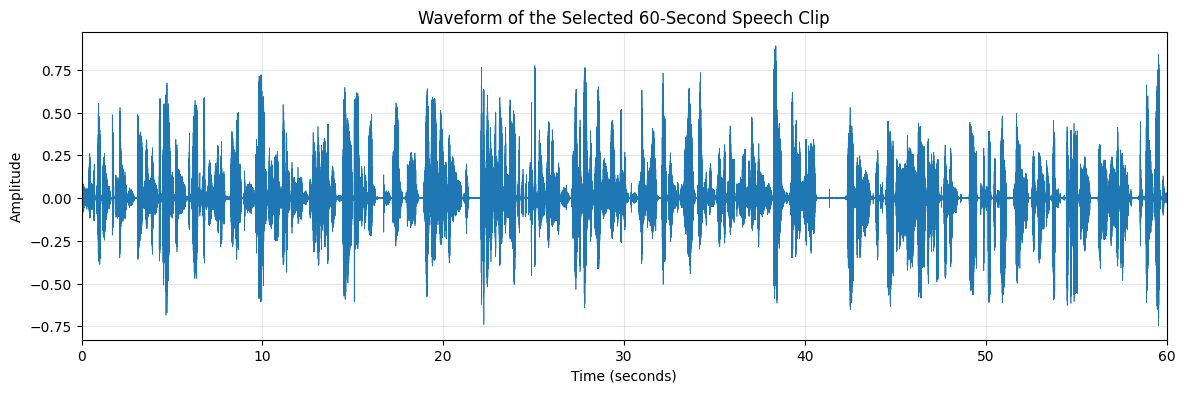

In [ ]:
import matplotlib.pyplot as plt

time_axis = np.arange(len(clip)) / TARGET_SR
plt.figure(figsize=(14, 4))
plt.plot(time_axis, clip, linewidth=0.5)
plt.title("Waveform of the Selected 60-Second Speech Clip")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.xlim(0, CLIP_SECONDS)
plt.grid(True, alpha=0.3)
plt.show()

### Log-Mel spectrogram and its analysis
The Log-Mel spectrogram displays the distribution of speech energy across time and frequency. Bright regions indicate higher energy, while darker regions indicate lower energy or pauses. These features help analyze speech patterns and provide useful input for understanding speech in ASR systems.



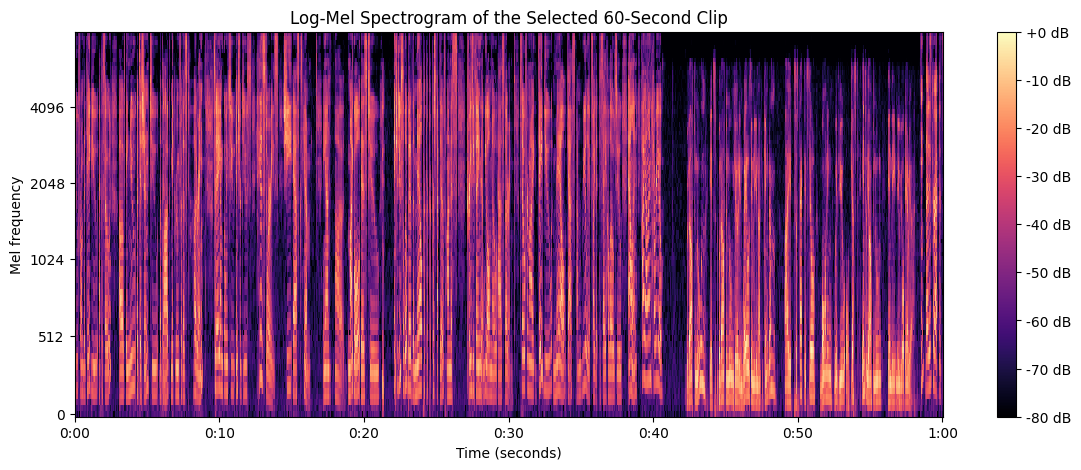

In [ ]:
import librosa.display

mel_power = librosa.feature.melspectrogram(
    y=clip,
    sr=TARGET_SR,
    n_fft=400,
    hop_length=160,
    n_mels=80,
    power=2.0
)
log_mel = librosa.power_to_db(mel_power, ref=np.max)

plt.figure(figsize=(14, 5))
librosa.display.specshow(
    log_mel,
    sr=TARGET_SR,
    hop_length=160,
    x_axis="time",
    y_axis="mel",
    cmap="magma"
)
plt.colorbar(format="%+2.0f dB")
plt.title("Log-Mel Spectrogram of the Selected 60-Second Clip")
plt.xlabel("Time (seconds)")
plt.ylabel("Mel frequency")
plt.show()

## ASR architecture diagram
The diagram shows how an Automatic Speech Recognition (ASR) system converts speech into text. The feature encoder extracts useful information from the audio, while the context network processes speech representations. The model generates token probabilities, and CTC decoding removes blank tokens and collapses repeated predictions to produce the recognized text.


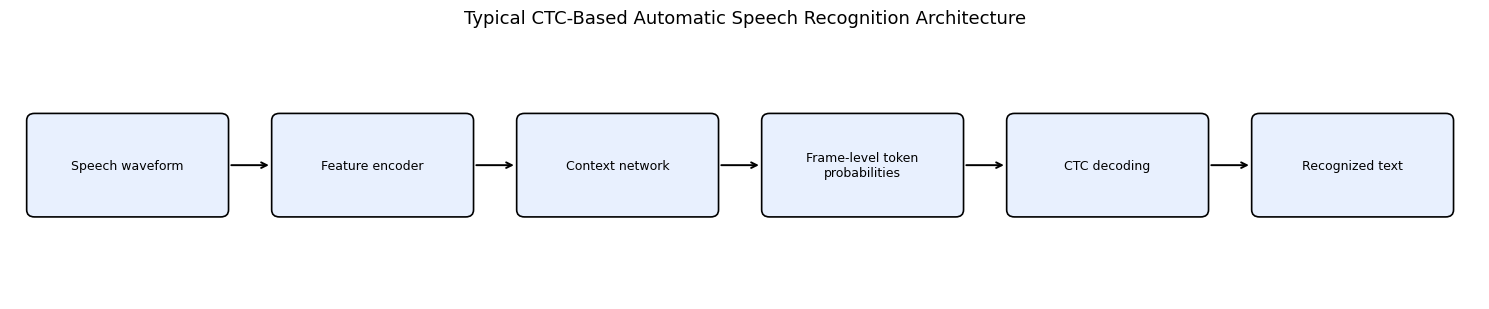

In [ ]:

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

labels = [
    "Speech waveform",
    "Feature encoder",
    "Context network",
    "Frame-level token\nprobabilities",
    "CTC decoding",
    "Recognized text"
]

fig, ax = plt.subplots(figsize=(15, 3.2))
ax.set_xlim(0, 15)
ax.set_ylim(0, 3)
ax.axis("off")

xs = [0.25, 2.75, 5.25, 7.75, 10.25, 12.75]

for i, (x, label) in enumerate(zip(xs, labels)):
    box = FancyBboxPatch(
        (x, 1.0), 1.9, 1.0,
        boxstyle="round,pad=0.08",
        edgecolor="black",
        facecolor="#e8f0fe",
        linewidth=1.2
    )
    ax.add_patch(box)

    ax.text(
        x + 0.95, 1.5, label,
        ha="center", va="center", fontsize=9
    )

    if i < len(xs) - 1:
        ax.annotate(
            "",
            xy=(xs[i + 1] - 0.08, 1.5),
            xytext=(x + 1.98, 1.5),
            arrowprops=dict(arrowstyle="->", lw=1.4)
        )

ax.set_title(
    "Typical CTC-Based Automatic Speech Recognition Architecture",
    fontsize=13
)

plt.tight_layout()
plt.show()


##CTC explanation

**Connectionist Temporal Classification (CTC)** is a training objective and decoding approach used when the exact alignment between audio frames and text labels is not known.

1. The acoustic model produces a probability distribution over tokens for each time frame.
2. The model's output sequence can be longer than the final text.
3. CTC introduces a special **blank** token and allows repeated token predictions.
4. During decoding, consecutive repeated tokens are collapsed and blank tokens are removed. For example, `h h _ e e l _ l o` becomes `hello` after collapsing repeats and removing blanks.
5. The decoder selects a likely text sequence from the frame-level predictions.

CTC does not magically remove stuttering from the original recording. The recognized text may omit repetitions, preserve them, or make other recognition errors depending on the model and audio.


## ASR model 1: Wav2Vec2 (CTC-based)

This uses a pretrained English Wav2Vec2 model. The model is loaded from Hugging Face.


In [ ]:
import torch
from transformers import pipeline

device = 0 if torch.cuda.is_available() else -1
print("ASR device:", "GPU" if device == 0 else "CPU")

wav2vec_asr = pipeline(
    task="automatic-speech-recognition",
    model="facebook/wav2vec2-base-960h",
    device=device
)
wav2vec_result = wav2vec_asr({"raw": clip, "sampling_rate": TARGET_SR})
wav2vec_text = wav2vec_result["text"].strip()

print("Wav2Vec2 transcript:")
print(wav2vec_text)

ASR device: CPU


Loading weights:   0%|          | 0/212 [00:00<?, ?it/s]

[transformers] Wav2Vec2ForCTC LOAD REPORT from: facebook/wav2vec2-base-960h
Key                        | Status  | 
---------------------------+---------+-
wav2vec2.masked_spec_embed | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Wav2Vec2 transcript:
EW FROM THE DEBUW EPISODE OF A NEW ADDITION TO THE BLOG MAKE ROOM FOR THI UTTERING TO DAY I'M GOING TO INTRODUCE HIS STORIES SHE ASKS HIM AND A MY GOAL IS TO INTRODUCE A LITTLE BIT OF THE MALE PERSPECTIVE ON THIS CRAZY THING THAT WE ALL KNOW AS STUTTERING SO FOR MY DEBEW MALE GUESSED I'M REALLY EXCITED TO SAY HULLO TO ALLEN HI ALLEN HOW ARE YOU GOOD AFTERNOON IT'S  GOOD AFTERNOON HERLIAN WAILS IN THE UNITED KINGDOM I SUSPECTED TILL MORNING WITH YOU OR JEFF INTO THE AFTERNOON IN THE NEW LOCARIA THAT IS CORRECTED


##  ASR model 2: Whisper

Whisper is a second ASR system with a different architecture and decoding method. This comparison is useful because it shows that different models can produce different transcripts from the same audio. Whisper is not a CTC model.


In [ ]:
from transformers import pipeline

whisper_asr = pipeline(
    task="automatic-speech-recognition",
    model="openai/whisper-base",
    device=device,
    chunk_length_s=30
)
whisper_result = whisper_asr(CLIP_PATH, generate_kwargs={"task": "transcribe"})
whisper_text = whisper_result["text"].strip()

print("Whisper transcript:")
print(whisper_text)

Loading weights:   0%|          | 0/245 [00:00<?, ?it/s]

[transformers] Using `chunk_length_s` is very experimental with seq2seq models. The results will not necessarily be entirely accurate and will have caveats. More information: https://github.com/huggingface/transformers/pull/20104. Ignore this warning with pipeline(..., ignore_warning=True). To use Whisper for long-form transcription, use rather the model's `generate` method directly as the model relies on its own chunking mechanism (cf. Whisper original paper, section 3.8. Long-form Transcription).


Whisper transcript:
from the debut episode of a new addition to the blog Make Room For This Tuttering. Today I'm going to introduce his stories. She asks him. And my goal is to introduce a little bit of the male perspective on this crazy thing that we all know as stuttering. So for my debut male guest, I'm really excited to say hello to Alan. Hi, Alan, how are you? Good afternoon. It's good afternoon here in Wales in the United Kingdom. I suspect it's still mourning with you or just into the afternoon in the New York area. That is correct.


## WER calculations

**Word Error Rate (WER)** measures word-level differences between a reference transcript and a hypothesis (ASR output):


WER = (S+D+I)/N * 100


- **S** = substitutions (a reference word is replaced by another word)
- **D** = deletions (a reference word is missing in the ASR output)
- **I** = insertions (an extra word appears in the ASR output)
- **N** = number of words in the reference transcript



In [ ]:
from jiwer import process_words
import pandas as pd


REFERENCE_TEXT = "from the debut episode of a new addition to the blog Make Room For this stuttering. today I'm going to introduce his stories. She asks him. and uh my goal is to introduce a little bit of the male perspective on this crazy thing that we all know as stuttering. so for my debut male guest, I'm really excited to say hello to Alan. Hi, Alan, how are you? Good afternoon. It's good afternoon here in Wales in the United Kingdom. I suspect it's still morning with you or just into the afternoon in the New York area. That is correct."

if not REFERENCE_TEXT.strip():
    print("REFERENCE_TEXT is empty. Listen to the clip, enter its verified transcript, and rerun this cell.")
    print("Current ASR hypotheses are shown below only for transcription assistance:")
    print("\nWav2Vec2:", wav2vec_text)
    print("\nWhisper:", whisper_text)
else:
    def score_wer(reference, hypothesis):
        result = process_words(reference, hypothesis)
        return {
            "WER": result.wer,
            "Substitutions": result.substitutions,
            "Deletions": result.deletions,
            "Insertions": result.insertions,
            "Reference words (N)": result.hits + result.substitutions + result.deletions,
        }

    wav2vec_scores = score_wer(REFERENCE_TEXT, wav2vec_text)
    whisper_scores = score_wer(REFERENCE_TEXT, whisper_text)

    wer_table = pd.DataFrame([
        {"Model": "Wav2Vec2 (CTC)", **wav2vec_scores},
        {"Model": "Whisper-base", **whisper_scores},
    ])
    display(wer_table.style.format({"WER": "{:.2%}"}))
    print("Lower WER is better. Interpret results alongside the actual audio and transcript.")

,Model,WER,Substitutions,Deletions,Insertions,Reference words (N)
0,Wav2Vec2 (CTC),100.00%,98,2,1,101
1,Whisper-base,6.93%,6,1,0,101


Lower WER is better. Interpret results alongside the actual audio and transcript.


## 11. ASR comparison table

This table compares the model outputs. WER values are populated only after the verified reference transcript is entered in Section 10. A lower WER indicates closer word-level agreement with that reference, but the result is specific to this clip and does not establish that one model is always better.


In [ ]:

from jiwer import process_words

if not REFERENCE_TEXT.strip():
    print("Please enter your verified reference transcript in Section 10 first.")
else:
    def calculate_wer(reference, hypothesis):
        result = process_words(reference, hypothesis)
        return result.wer

    wav2vec_wer = calculate_wer(REFERENCE_TEXT, wav2vec_text)
    whisper_wer = calculate_wer(REFERENCE_TEXT, whisper_text)

    print("ASR MODEL COMPARISON")
    print("-" * 40)
    print(f"Wav2Vec2 (CTC) WER: {wav2vec_wer:.2%}")
    print(f"Whisper-base WER:    {whisper_wer:.2%}")

    if wav2vec_wer < whisper_wer:
        print("\nBetter model: Wav2Vec2 (CTC)")
        print("It achieved a lower WER, meaning fewer word-level errors.")
    elif whisper_wer < wav2vec_wer:
        print("\nBetter model: Whisper-base")
        print("It achieved a lower WER, meaning fewer word-level errors.")
    else:
        print("\nBoth models achieved the same WER.")

    print("\nLower WER indicates better recognition accuracy.")


ASR MODEL COMPARISON
----------------------------------------
Wav2Vec2 (CTC) WER: 100.00%
Whisper-base WER:    6.93%

Better model: Whisper-base
It achieved a lower WER, meaning fewer word-level errors.

Lower WER indicates better recognition accuracy.


## 12. Text-to-Speech (TTS)

The following cell converts the selected recognized transcript into synthesized speech using Google Text-to-Speech (gTTS). By default it uses the Whisper transcript; change `TTS_SOURCE` to `"wav2vec"` to use Wav2Vec2.


In [ ]:
from gtts import gTTS
from IPython.display import Audio, display
from pathlib import Path

TTS_SOURCE = "whisper"  # either "whisper" or "wav2vec"
tts_text = whisper_text if TTS_SOURCE.lower() == "whisper" else wav2vec_text

if not tts_text.strip():
    raise ValueError("Selected ASR transcript is empty; run the ASR cells first.")

tts = gTTS(text=tts_text, lang="en", slow=False)
TTS_PATH = "/content/tts_output.mp3"
tts.save(TTS_PATH)

print("TTS text:")
print(tts_text)
print("\nGenerated speech:")
display(Audio(TTS_PATH))

print("TTS audio saved to:", TTS_PATH)

TTS text:
from the debut episode of a new addition to the blog Make Room For This Tuttering. Today I'm going to introduce his stories. She asks him. And my goal is to introduce a little bit of the male perspective on this crazy thing that we all know as stuttering. So for my debut male guest, I'm really excited to say hello to Alan. Hi, Alan, how are you? Good afternoon. It's good afternoon here in Wales in the United Kingdom. I suspect it's still mourning with you or just into the afternoon in the New York area. That is correct.

Generated speech:


TTS audio saved to: /content/tts_output.mp3


In [ ]:
print("UNIT 3 SPEECH RECOGNITION ACTIVITY — RESULTS SUMMARY")
print("=" * 55)
print(f"Selected source: {Path(AUDIO_PATH).name}")
print(f"Clip interval: {CLIP_START_SECONDS}–{CLIP_START_SECONDS + CLIP_SECONDS} seconds")
print(f"Sample rate: {TARGET_SR} Hz, mono")
print("\nObserved speech disruption (fill in after listening): [describe what is actually audible]")
print("\nWav2Vec2 transcript:")
print(wav2vec_text)
print("\nWhisper transcript:")
print(whisper_text)

if REFERENCE_TEXT.strip():
    print("\nVerified reference transcript:")
    print(REFERENCE_TEXT)
    print(f"\nWav2Vec2 WER: {wav2vec_scores['WER']:.2%}")
    print(f"Whisper WER: {whisper_scores['WER']:.2%}")
else:
    print("\nWER not calculated: add a manually verified reference transcript in Section 10.")

print("\nTTS output path:", TTS_PATH if "TTS_PATH" in globals() else "Run Section 12 first")

UNIT 3 SPEECH RECOGNITION ACTIVITY — RESULTS SUMMARY
Selected source: stutter_audio.mp3
Clip interval: 20–80 seconds
Sample rate: 16000 Hz, mono

Observed speech disruption (fill in after listening): [describe what is actually audible]

Wav2Vec2 transcript:
EW FROM THE DEBUW EPISODE OF A NEW ADDITION TO THE BLOG MAKE ROOM FOR THI UTTERING TO DAY I'M GOING TO INTRODUCE HIS STORIES SHE ASKS HIM AND A MY GOAL IS TO INTRODUCE A LITTLE BIT OF THE MALE PERSPECTIVE ON THIS CRAZY THING THAT WE ALL KNOW AS STUTTERING SO FOR MY DEBEW MALE GUESSED I'M REALLY EXCITED TO SAY HULLO TO ALLEN HI ALLEN HOW ARE YOU GOOD AFTERNOON IT'S  GOOD AFTERNOON HERLIAN WAILS IN THE UNITED KINGDOM I SUSPECTED TILL MORNING WITH YOU OR JEFF INTO THE AFTERNOON IN THE NEW LOCARIA THAT IS CORRECTED

Whisper transcript:
from the debut episode of a new addition to the blog Make Room For This Tuttering. Today I'm going to introduce his stories. She asks him. And my goal is to introduce a little bit of the male perspective 